# Stage 6: Data Visualisation & Insights

**Financial Forecasting & Variance Analysis** | Stage 6 of 6 | ← [Stage 5: Data Preparation for Reporting](../05-data-preparation-for-reporting/05-data-preparation-for-reporting.ipynb) | [Project README](../../README.md)

> Present the evidence for each research sub-question visually and state findings that are calculated from the data, not written by hand.

| Reads | Writes |
| --- | --- |
| `data/gold/*.parquet` | Charts and the executive summary (in this notebook) |

In [1]:
import sys
from pathlib import Path

# Locate the repo root (the folder that holds python/config.py) and import the shared modules
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "python" / "config.py").exists())
sys.path.insert(0, str(ROOT / "python"))

import pandas as pd
import config

pd.set_option("display.float_format", "{:,.2f}".format)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

import numpy as np
from IPython.display import Markdown

import charts
import warehouse

charts.apply_style()
plt = charts.plt
con = warehouse.connect()
q = lambda sql: warehouse.query(con, sql)

monthly = q("SELECT * FROM gold_monthly_spend WHERE is_complete_month ORDER BY month_start")
backtest = q("SELECT * FROM gold_forecast_backtest ORDER BY month_start")
scores = q("SELECT * FROM gold_forecast_scores")
ahead = q("SELECT * FROM gold_forecast_ahead ORDER BY month_start")
importance = q("SELECT * FROM gold_forecast_feature_importance")
var_tests = q("SELECT * FROM gold_variance_tests")
customers = q("SELECT * FROM gold_customer_segments")
segments = q("SELECT * FROM gold_segment_profile")
fraud = q("SELECT * FROM gold_fraud_profile")
dq = q("SELECT * FROM gold_data_quality_checks")
best_model = scores.iloc[0]["model"]

## 6.1 Forecasting

### Monthly net spend and the 12-month outlook

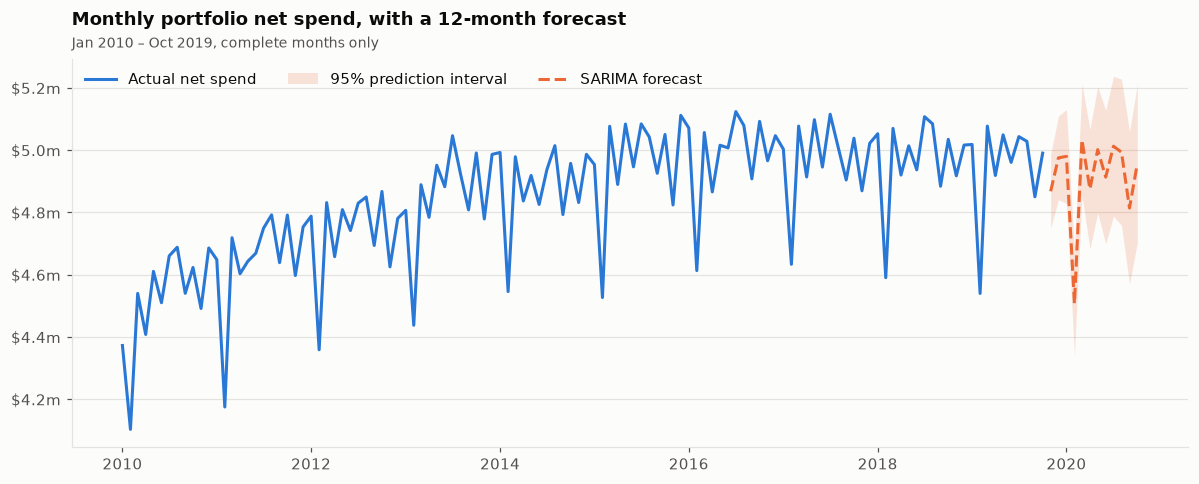

In [2]:
fig, ax = plt.subplots()
ax.plot(monthly["month_start"], monthly["net_spend"], color=charts.SERIES[0], label="Actual net spend")
ax.fill_between(ahead["month_start"], ahead["lower"], ahead["upper"], color=charts.SERIES[1], alpha=0.18,
                linewidth=0, label="95% prediction interval")
ax.plot(ahead["month_start"], ahead["forecast"], color=charts.SERIES[1], linestyle="--", label="SARIMA forecast")
charts.money_axis(ax, "y")
ax.legend(loc="upper left", ncols=3)
charts.finish(ax, "Monthly portfolio net spend, with a 12-month forecast",
              f"{monthly['month_start'].min():%b %Y} – {monthly['month_start'].max():%b %Y}, complete months only")
charts.show()

### Backtest: one-step-ahead forecasts against actuals (last 24 months)

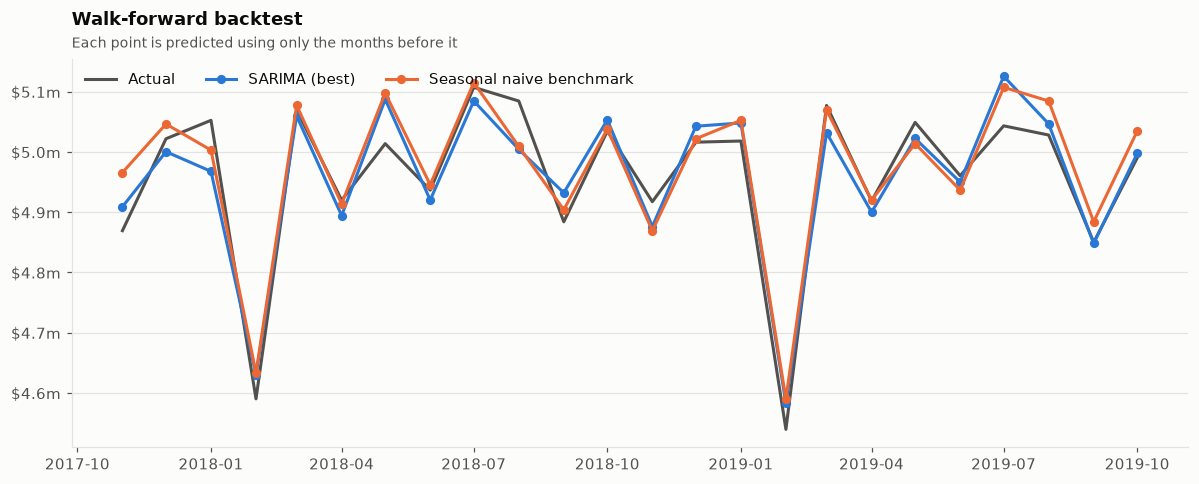

In [3]:
fig, ax = plt.subplots()
ax.plot(backtest["month_start"], backtest["actual"], color=charts.TEXT_2, linewidth=2, label="Actual")
ax.plot(backtest["month_start"], backtest[best_model], color=charts.SERIES[0], marker="o", label=f"{best_model} (best)")
ax.plot(backtest["month_start"], backtest["Seasonal naive (same month last year)"], color=charts.SERIES[1],
        marker="o", label="Seasonal naive benchmark")
charts.money_axis(ax, "y")
ax.legend(loc="upper left", ncols=3)
charts.finish(ax, "Walk-forward backtest", "Each point is predicted using only the months before it")
charts.show()

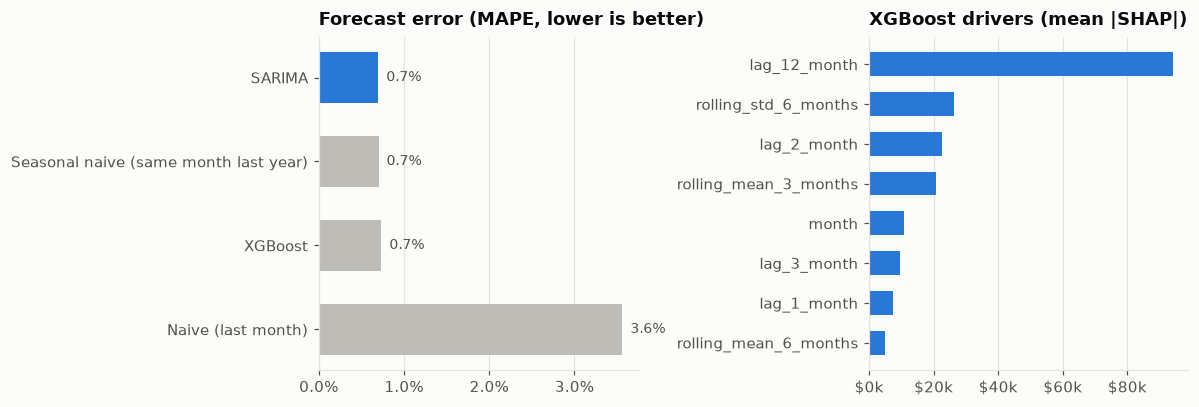

,model,MAE,RMSE,MAPE_pct,R2,MAPE_vs_seasonal_naive_pct
0,SARIMA,"34,701.14","42,037.05",0.70,0.91,0.36
1,Seasonal naive (same month last year),"34,671.56","43,743.79",0.70,0.90,0.00
2,XGBoost,"36,078.27","47,981.44",0.73,0.88,-4.72
3,Naive (last month),"174,439.55","230,547.74",3.56,-1.80,-407.53


In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
s = scores.sort_values("MAPE_pct", ascending=True)
ax1.barh(s["model"], s["MAPE_pct"], color=[charts.SERIES[0] if m == best_model else charts.NEUTRAL for m in s["model"]], height=0.6)
ax1.invert_yaxis()
ax1.xaxis.set_major_formatter(charts.pct(1))
ax1.grid(axis="x"); ax1.grid(axis="y", visible=False)
for y, v in enumerate(s["MAPE_pct"]):
    ax1.text(v, y, f"  {v:.1f}%", va="center", color=charts.TEXT_2, fontsize=9)
charts.finish(ax1, "Forecast error (MAPE, lower is better)")

imp = importance.sort_values("mean_abs_shap")
ax2.barh(imp["feature"], imp["mean_abs_shap"], color=charts.SERIES[0], height=0.6)
charts.money_axis(ax2, "x")
ax2.grid(axis="x"); ax2.grid(axis="y", visible=False)
charts.finish(ax2, "XGBoost drivers (mean |SHAP|)")
charts.show()
scores.round(3)

## 6.2 Variance analysis

### Portfolio variance by month

The sum of customer variances against their trailing three-month budgets. Blue bars are favourable (above budget), red bars adverse (below).

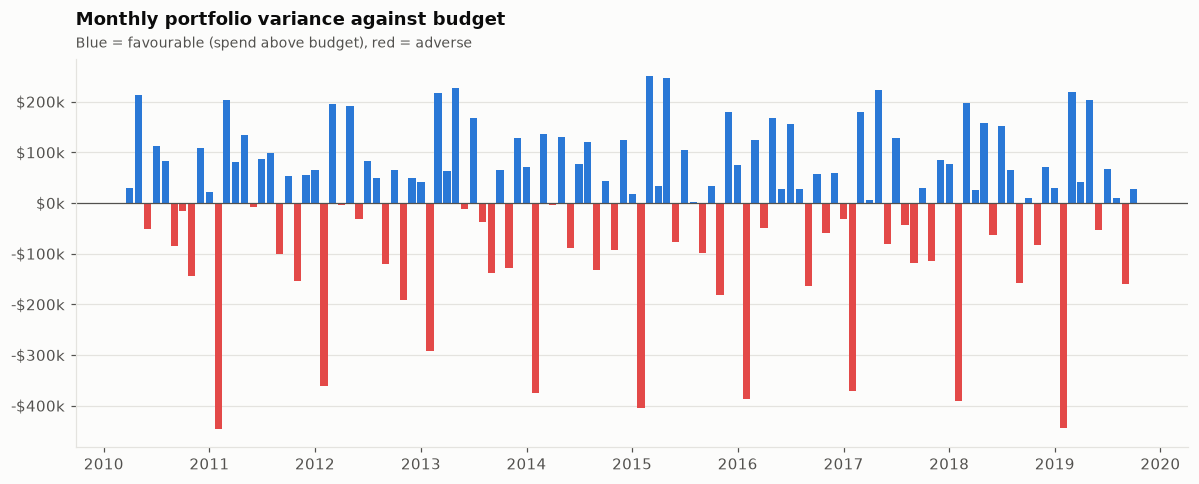

In [5]:
var_month = q("""
    SELECT month_start, SUM(variance) AS variance, SUM(budget_spend) AS budget,
           AVG(CAST(is_material AS INTEGER)) * 100 AS material_pct
    FROM gold_customer_monthly_variance GROUP BY 1 ORDER BY 1""")

fig, ax = plt.subplots()
ax.bar(var_month["month_start"], var_month["variance"], width=25,
       color=np.where(var_month["variance"] >= 0, charts.FAVOURABLE, charts.ADVERSE))
ax.axhline(0, color=charts.TEXT_2, linewidth=0.8)
charts.money_axis(ax, "y")
charts.finish(ax, "Monthly portfolio variance against budget",
              "Blue = favourable (spend above budget), red = adverse")
charts.show()

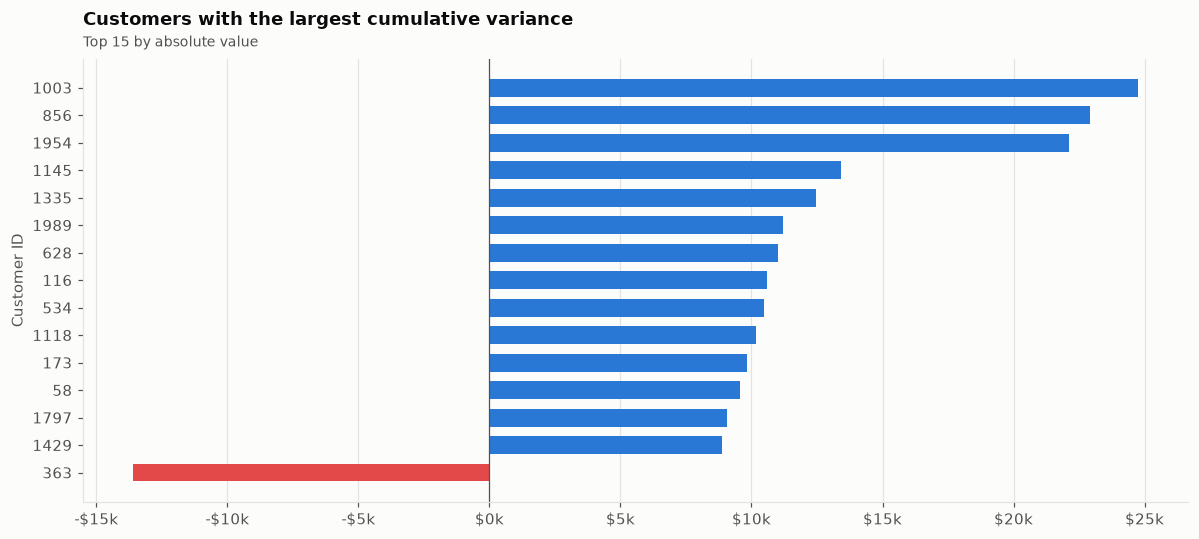

In [6]:
top = q("""
    SELECT user_id, SUM(variance) AS cumulative_variance
    FROM gold_customer_monthly_variance GROUP BY 1
    ORDER BY ABS(SUM(variance)) DESC LIMIT 15""").sort_values("cumulative_variance")

fig, ax = plt.subplots(figsize=(11, 5))
ax.barh(top["user_id"].astype(str), top["cumulative_variance"], height=0.65,
        color=np.where(top["cumulative_variance"] >= 0, charts.FAVOURABLE, charts.ADVERSE))
ax.axvline(0, color=charts.TEXT_2, linewidth=0.8)
charts.money_axis(ax, "x")
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
charts.finish(ax, "Customers with the largest cumulative variance", "Top 15 by absolute value", ylabel="Customer ID")
charts.show()

## 6.3 Customer value and risk

### Segments: share of customers vs share of spend

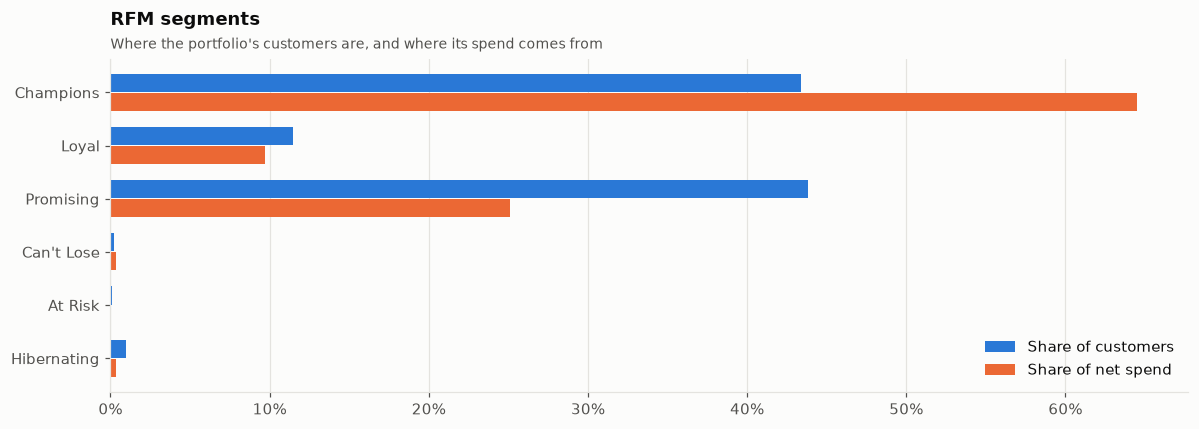

,segment,customers,avg_recency_days,avg_txn_per_month,avg_monthly_spend,net_spend,customer_share_pct,spend_share_pct
0,Champions,529,1.00,130.70,"6,010.80","368,723,602.40",43.40,64.50
1,Loyal,140,1.00,88.10,"3,423.90","55,365,486.00",11.50,9.70
2,Promising,534,1.20,61.20,"2,345.50","143,438,187.20",43.80,25.10
3,Can't Lose,3,"1,036.00",162.80,"8,513.20","2,154,093.60",0.20,0.40
4,At Risk,1,"1,127.00",104.00,"2,431.80","196,979.60",0.10,0.00
5,Hibernating,12,"1,069.80",51.80,"2,088.60","1,957,173.50",1.00,0.30


In [7]:
seg = segments.set_index("segment")
fig, ax = plt.subplots(figsize=(11, 4))
y = np.arange(len(seg))
ax.barh(y - 0.18, seg["customer_share_pct"], height=0.34, color=charts.SERIES[0], label="Share of customers")
ax.barh(y + 0.18, seg["spend_share_pct"], height=0.34, color=charts.SERIES[1], label="Share of net spend")
ax.set_yticks(y, seg.index)
ax.invert_yaxis()
ax.xaxis.set_major_formatter(charts.pct(0))
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
charts.finish(ax, "RFM segments", "Where the portfolio's customers are, and where its spend comes from")
charts.show()
segments.round(1)

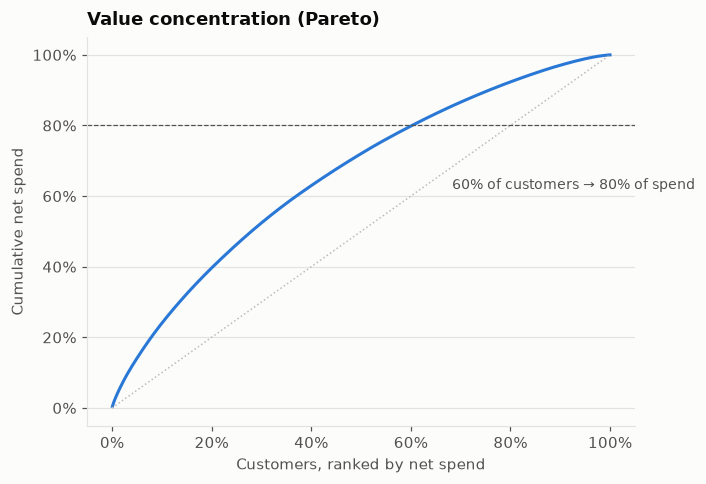

In [8]:
fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.plot(customers["customer_share_pct"], customers["cumulative_spend_share_pct"], color=charts.SERIES[0])
ax.plot([0, 100], [0, 100], color=charts.NEUTRAL, linewidth=1, linestyle=":")
pareto_80 = customers.loc[customers["cumulative_spend_share_pct"] >= 80, "customer_share_pct"].iloc[0]
ax.axhline(80, color=charts.TEXT_2, linewidth=0.8, linestyle="--")
ax.annotate(f"{pareto_80:.0f}% of customers → 80% of spend", (pareto_80, 80), xytext=(pareto_80 + 8, 62),
            arrowprops={"arrowstyle": "-", "color": charts.TEXT_2}, color=charts.TEXT_2, fontsize=9)
ax.xaxis.set_major_formatter(charts.pct(0)); ax.yaxis.set_major_formatter(charts.pct(0))
charts.finish(ax, "Value concentration (Pareto)", xlabel="Customers, ranked by net spend", ylabel="Cumulative net spend")
charts.show()

### Fraud rate by transaction attribute (labelled transactions only)

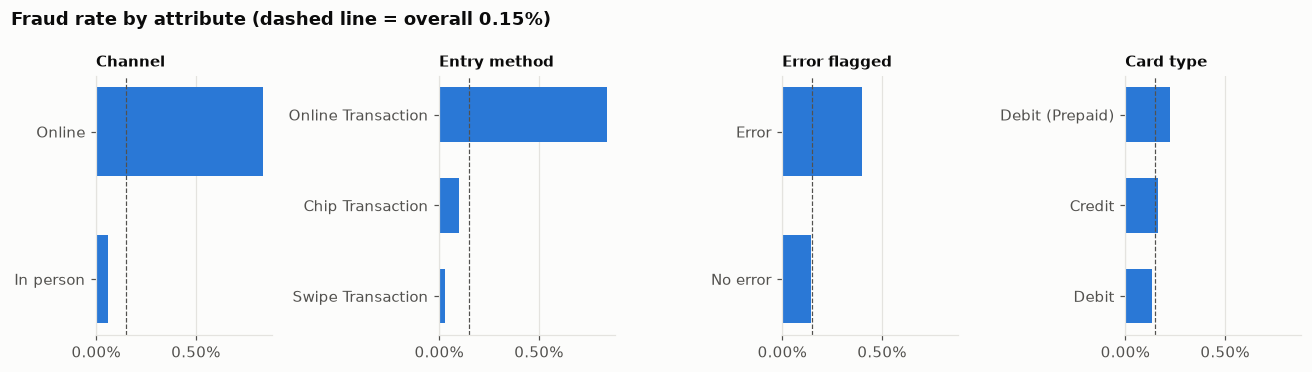

In [9]:
dims = ["Channel", "Entry method", "Error flagged", "Card type"]
fig, axes = plt.subplots(1, len(dims), figsize=(12, 3.4), sharex=True)
overall = fraud.loc[fraud["dimension"] == "Channel", "fraud_transactions"].sum() / \
          fraud.loc[fraud["dimension"] == "Channel", "labelled_transactions"].sum() * 100
for ax, d in zip(axes, dims):
    f = fraud.loc[fraud["dimension"] == d].sort_values("fraud_rate")
    ax.barh(f["dimension_value"], f["fraud_rate"] * 100, color=charts.SERIES[0], height=0.6)
    ax.axvline(overall, color=charts.TEXT_2, linewidth=0.8, linestyle="--")
    ax.xaxis.set_major_formatter(charts.pct(2))
    ax.grid(axis="x"); ax.grid(axis="y", visible=False)
    ax.set_title(d, fontsize=10)
fig.suptitle(f"Fraud rate by attribute (dashed line = overall {overall:.2f}%)", x=0.01, ha="left", fontweight="bold")
charts.show()

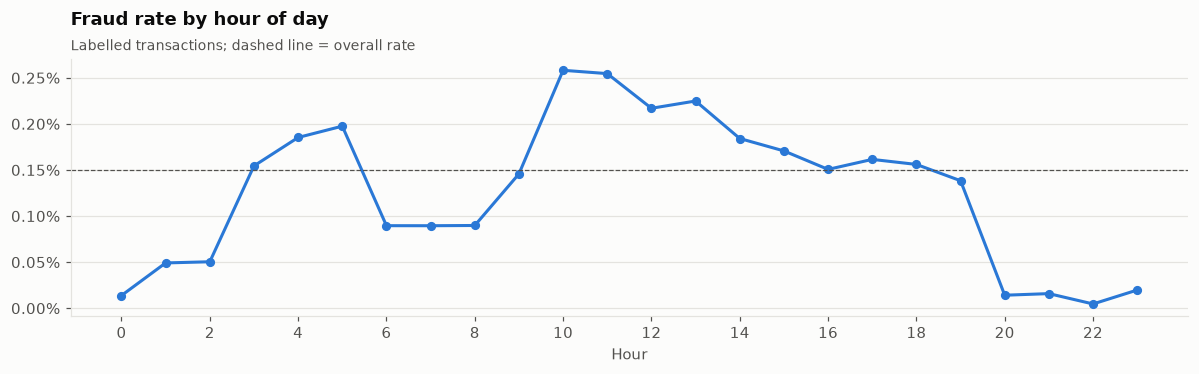

In [10]:
hours = fraud.loc[fraud["dimension"] == "Hour of day"].sort_values("dimension_value")
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(hours["dimension_value"].astype(int), hours["fraud_rate"] * 100, color=charts.SERIES[0], marker="o")
ax.axhline(overall, color=charts.TEXT_2, linewidth=0.8, linestyle="--")
ax.yaxis.set_major_formatter(charts.pct(2))
ax.set_xticks(range(0, 24, 2))
charts.finish(ax, "Fraud rate by hour of day", "Labelled transactions; dashed line = overall rate", xlabel="Hour")
charts.show()

## 6.4 Executive summary

Every sentence below is generated from the gold tables, so the summary updates when the pipeline is re-run and can't drift from the evidence.

In [11]:
best = scores.iloc[0]
bench = scores.loc[scores["model"].str.startswith("Seasonal naive")].iloc[0]
beats_bench = best["MAPE_pct"] < bench["MAPE_pct"]
t_row = var_tests.loc[var_tests["test"].str.startswith("One-sample")].iloc[0]
w_row = var_tests.loc[var_tests["test"].str.startswith("Wilcoxon")].iloc[0]
var_all = q("""SELECT AVG(CAST(variance_type = 'Favourable' AS INTEGER)) * 100 AS fav_pct,
                      AVG(CAST(is_material AS INTEGER)) * 100 AS material_pct,
                      SUM(variance) AS net_var, SUM(budget_spend) AS budget
               FROM gold_customer_monthly_variance""").iloc[0]
top10_share = customers.loc[customers["customer_share_pct"] <= 10, "net_spend"].sum() / customers["net_spend"].sum() * 100
champ = segments.set_index("segment").reindex(["Champions"]).iloc[0]
fr_ch = fraud.loc[fraud["dimension"] == "Channel"].set_index("dimension_value")["fraud_rate"] * 100
fails = int((dq["status"] == "FAIL").sum())
width = ((ahead["upper"] - ahead["lower"]) / ahead["forecast"]).mean() * 100
gain = (1 - best["MAPE_pct"] / bench["MAPE_pct"]) * 100
net_var_pct = var_all["net_var"] / var_all["budget"] * 100
if t_row["p_value"] >= 0.05:
    var_verdict = "A trailing three-month average is therefore an unbiased, if noisy, budget."
elif abs(net_var_pct) < 1:
    var_verdict = (f"The bias is economically negligible ({net_var_pct:+.1f}% of budget): with this many observations "
                   "even a tiny systematic gap tests as significant. The budget is fit for portfolio planning, but at "
                   f"customer level it is noisy, with {var_all['material_pct']:.0f}% of customer-months off by 10% or more.")
else:
    var_verdict = (f"The bias is material ({net_var_pct:+.1f}% of budget), so a trailing three-month average needs a "
                   "seasonal or trend adjustment before it is used as a budget.")
if best["model"] == bench["model"]:
    verdict = "No model beat the seasonal-naive benchmark: last year's same month was the best forecast."
elif gain < 5:
    verdict = (f"That is only {gain:.1f}% better than the seasonal-naive benchmark (MAPE {bench['MAPE_pct']:.2f}%), "
               "so the added model complexity buys little: the series is dominated by a stable seasonal pattern.")
else:
    verdict = f"It beat the seasonal-naive benchmark (MAPE {bench['MAPE_pct']:.2f}%) by {gain:.0f}%."


Markdown(f"""
**1. Forecasting.** Over a {len(backtest)}-month walk-forward backtest, **{best['model']}** was the most accurate model
(MAPE {best['MAPE_pct']:.2f}%, RMSE ${best['RMSE']:,.0f}).
{verdict}
The 12-month SARIMA outlook carries an average 95% interval width of ±{width / 2:.0f}% of the point forecast,
which is the planning uncertainty a budget built on it would need to absorb.

**2. Variance.** {var_all['fav_pct']:.0f}% of customer-months came in above budget and {var_all['material_pct']:.0f}% were material
(≥ 10% of budget). Net variance was ${var_all['net_var']:,.0f} against ${var_all['budget']:,.0f} of budget
({var_all['net_var'] / var_all['budget'] * 100:+.1f}%). At customer level the mean variance is
{'statistically significant' if t_row['p_value'] < 0.05 else 'not statistically significant'} (t-test p = {t_row['p_value']:.3g};
Wilcoxon p = {w_row['p_value']:.3g}). {var_verdict}

**3. Customer value and risk.** Value is {'highly concentrated' if top10_share >= 40 else 'moderately concentrated' if top10_share >= 20 else 'broadly spread'}: the top 10% of customers generate
{top10_share:.0f}% of net spend, and {pareto_80:.0f}% of customers generate 80%.
{f"Champions are {champ['customer_share_pct']:.0f}% of customers but {champ['spend_share_pct']:.0f}% of spend." if champ.notna().all() else ""}
Among labelled transactions, the fraud rate is {fr_ch.get('Online', float('nan')):.2f}% online vs {fr_ch.get('In person', float('nan')):.2f}% in person.

**Data quality.** {'All integrity controls passed.' if fails == 0 else f'**{fails} integrity control(s) failed** and must be resolved before these findings are relied on (see stage 3).'}
""")


**1. Forecasting.** Over a 24-month walk-forward backtest, **SARIMA** was the most accurate model
(MAPE 0.70%, RMSE $42,037).
That is only 0.4% better than the seasonal-naive benchmark (MAPE 0.70%), so the added model complexity buys little: the series is dominated by a stable seasonal pattern.
The 12-month SARIMA outlook carries an average 95% interval width of ±4% of the point forecast,
which is the planning uncertainty a budget built on it would need to absorb.

**2. Variance.** 48% of customer-months came in above budget and 65% were material
(≥ 10% of budget). Net variance was $586,763 against $557,212,162 of budget
(+0.1%). At customer level the mean variance is
statistically significant (t-test p = 2.89e-12;
Wilcoxon p = 1.38e-13). The bias is economically negligible (+0.1% of budget): with this many observations even a tiny systematic gap tests as significant. The budget is fit for portfolio planning, but at customer level it is noisy, with 65% of customer-months off by 10% or more.

**3. Customer value and risk.** Value is moderately concentrated: the top 10% of customers generate
24% of net spend, and 60% of customers generate 80%.
Champions are 43% of customers but 64% of spend.
Among labelled transactions, the fraud rate is 0.84% online vs 0.06% in person.

**Data quality.** All integrity controls passed.


## 6.5 Limitations

1. **Provenance.** The publisher doesn't document how the records were produced. These findings show the method; they don't describe a real bank.
2. **Volume, not revenue.** Net spend is cardholder transaction value. Issuer revenue would need interchange, fee and interest data.
3. **Statistical budget.** The variance budget is a trailing average, not an approved plan, and it inherits that average's lag when the series trends or is seasonal.
4. **Partial fraud labels.** Fraud rates describe labelled transactions only. If labelling wasn't random, the rates are biased in an unknown direction.
5. **Forecast scope.** The forecast is one series at portfolio level and doesn't account for shocks after the extract ends. Prediction intervals assume the SARIMA error structure holds.

← [Stage 5: Data Preparation for Reporting](../05-data-preparation-for-reporting/05-data-preparation-for-reporting.ipynb) | [Project README](../../README.md)